# Figure 2 - Pooled IPO trajectories and sea ice concentration anomalies

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.gridspec as gridspec
import matplotlib.path as mpath
import cartopy.crs as ccrs
import numpy as np
import scipy.stats as stats
import glob

In [2]:
model_names = [
    'ACCESS-ESM1-5', 'CESM2-LENS', 'CanESM5', 'EC-Earth3', 
    'MIROC6', 'MPI-ESM1-2-LR', 'CanESM2', 'CESM1'
]

model_years = {
    'CanESM5':[1850,2100], 'CESM2-LENS':[1850,2100], 'ACCESS-ESM1-5':[1850,2100], 
    'MPI-ESM1-2-LR':[1850,2100], 'MIROC6':[1850,2100], 'EC-Earth3':[1850,2100], 
    'CanESM2':[1950,2100], 'CESM1':[1920,2100]
}

mem_n = {'ACCESS-ESM1-5':40, 'CanESM5':49, 'CESM2-LENS':50,
         'EC-Earth3':50, 'MIROC6':50, 'MPI-ESM1-2-LR':30, 'CanESM2':50, 'CESM1':40}

model_names_title = [
    'ACCESS-ESM1-5',
    'CanESM5     ',
    'CESM2-LENS   ',
    'EC-Earth3     ',
    'MIROC6       ',
    'MPI-ESM1-2-LR',
    'CanESM2     ',
    'CESM1       '
]

## Load Sea Ice Extent (SIE) data

In [3]:
#load the September SIE
All_SIE = xr.open_dataset('/glade/work/cwpowell/ice-free/sea_ice_data/All_Model_September_SIE.nc')

sep_SIE = {}

for model_name in model_names:
    #drop NA members caused by models with different member names
    sep_SIE[model_name] = All_SIE[model_name].dropna(dim='member', how='all').dropna(dim='time', how='all')
    
#compute a rolling 11-year average
sep_SIE_11yr = {}

for model_name in model_names:
    sep_SIE_11yr[model_name] = sep_SIE[model_name].rolling(time=11, center=True).mean()

## Load the IPO and compute trajectories by IPO phase persistence

In [4]:
path = ('/glade/work/cwpowell/low-freq-trajectories/SST_for_IPO/'
        'IPO_per_Screen_Deser/IPO_11yr_annual_av_TPI_all_models.nc')

IPO_models = {model_name: xr.open_dataarray(path, group=model_name)
              for model_name in model_names}

In [5]:
#trajectories starting at 4.2-5.2 SIE in increments of 0.1 million sq km
#IPO defined as 10 years of persistence
IPO_pos_dict = {}
IPO_neg_dict = {}
IPO_pos_dict_m = {}
IPO_neg_dict_m = {}
SIE_all_mem = {}

for model_name in model_names:
    print(model_name)

    IPO_pos_ = []
    IPO_neg_ = []
    IPO_pos_m = []
    IPO_pos_pos_mems = []
    IPO_pos_neg_mems = []
    IPO_pos_mems = []
    IPO_neg_m = []
    IPO_neg_pos_mems = []
    IPO_neg_neg_mems = []
    IPO_neg_mems = []
    SIE_mem_all_start = []
    
    for start_SIE in np.arange(4.2,5.21,0.1):
        
        IPO_pos_mem = []
        IPO_neg_mem = []
        IPO_pos_mem_m = []
        IPO_neg_mem_m = []
        all_SIE_mem = []
        for mem_ in IPO_models[model_name]['member']:
            if mem_ == 'r49i1p1':
                continue
            
            #find latest matching year to SIE, define start_year
            start_yr_mem = int(sep_SIE_11yr[model_name]['time'].where(
                (sep_SIE_11yr[model_name].sel(member=mem_) - start_SIE) < 0).min('time'))

            #always append the SIE with years corrected to 0-51
            if model_name == 'CanESM2': #need as many years as possible
                mem_SIE_traj = sep_SIE_11yr[model_name].sel(member=mem_).sel(
                    time=slice(start_yr_mem,start_yr_mem+60))
                mem_SIE_traj['time'] = np.arange(0,61)
            else:
                mem_SIE_traj = sep_SIE_11yr[model_name].sel(member=mem_).sel(
                    time=slice(start_yr_mem,start_yr_mem+54))
                mem_SIE_traj['time'] = np.arange(0,55)
                
            all_SIE_mem.append(mem_SIE_traj)
            
            ###### persistence metric of 10+ years in same phase
            IPO_pos = (IPO_models[model_name].sel(member=mem_).sel(
                year=slice(start_yr_mem-9,start_yr_mem))>0).min('year')==True
            IPO_neg = (IPO_models[model_name].sel(member=mem_).sel(
                year=slice(start_yr_mem-9,start_yr_mem))<0).min('year')==True
            
            if IPO_pos:
                IPO_pos_mem.append(mem_SIE_traj)
                IPO_pos_mem_m.append(mem_SIE_traj-start_SIE)
                IPO_pos_mems.append(str(mem_.values))
            elif IPO_neg:
                IPO_neg_mem.append(mem_SIE_traj)
                IPO_neg_mem_m.append(mem_SIE_traj-start_SIE)
                IPO_neg_mems.append(str(mem_.values))
                
        
        #if no examples of both criteria being fulfilled, instead append the 
        #ensemble mean
        ens_mean = xr.concat((all_SIE_mem),dim='member').mean('member')
            
        #also calculate the standard deviation, if at least 2 trajectories        
        IPO_pos_.append(xr.concat((IPO_pos_mem),dim='member').mean('member'))
        IPO_neg_.append(xr.concat((IPO_neg_mem),dim='member').mean('member'))
      
        IPO_pos_m.append(xr.concat((IPO_pos_mem_m),dim='member'))
        IPO_neg_m.append(xr.concat((IPO_neg_mem_m),dim='member'))     
        
        SIE_mem_all_start.append(xr.concat((all_SIE_mem),dim='member'))
        
    
    print('IPO+ mem:',len(np.unique(IPO_pos_mems)), 'IPO- mem:',len(np.unique(IPO_neg_mems)))
    
    IPO_pos_dict[model_name] = xr.concat((IPO_pos_),
                                                  dim='start_SIE').mean('start_SIE')
    IPO_neg_dict[model_name] = xr.concat((IPO_neg_),
                                                  dim='start_SIE').mean('start_SIE')
    
    IPO_pos_dict_m[model_name] = xr.concat((IPO_pos_m),dim='start_SIE')
    IPO_neg_dict_m[model_name] = xr.concat((IPO_neg_m),dim='start_SIE')
    
    SIE_all_mem[model_name] = xr.concat((SIE_mem_all_start),dim='start_SIE').mean('start_SIE')

ACCESS-ESM1-5
IPO+ mem: 19 IPO- mem: 12
CESM2-LENS
IPO+ mem: 10 IPO- mem: 16
CanESM5
IPO+ mem: 13 IPO- mem: 13
EC-Earth3
IPO+ mem: 13 IPO- mem: 17
MIROC6
IPO+ mem: 14 IPO- mem: 18
MPI-ESM1-2-LR
IPO+ mem: 7 IPO- mem: 7
CanESM2
IPO+ mem: 21 IPO- mem: 13
CESM1
IPO+ mem: 7 IPO- mem: 12


## Load the spatial sea ice concentration data

In [6]:
#read the SIC composite trajectory data by IPO phase
path = '/glade/work/cwpowell/ice-free/SIC_trajectories/'
suffix = '_start_42_52_sq_km_regrid.nc'

pos = xr.open_dataset(f'{path}SIC_traj_IPO_pos{suffix}')
neg = xr.open_dataset(f'{path}SIC_traj_IPO_neg{suffix}')
ensemble = xr.open_dataset(f'{path}SIC_traj_ensemble{suffix}')

def by_model(field):
    return {model_name: field.sel(model=model_name, drop=True) for model_name in model_names}

IPO_pos, IPO_pos_SD = by_model(pos['SIC']), by_model(pos['SIC_SD'])
IPO_neg, IPO_neg_SD = by_model(neg['SIC']), by_model(neg['SIC_SD'])
all_mem, ens_max = by_model(ensemble['SIC_mean']), by_model(ensemble['SIC_max'])
all_mem_SD = by_model(ensemble['SIC_SD'])

In [7]:
#load 1x1 degree land mask and pole hole for plotting
CanESM2_sftlf = xr.open_dataset('/glade/work/cwpowell/ice-free/SIC_trajectories/CanESM2_sftlf_regrid_1x1_deg.nc')
ones_pole_hole = (IPO_pos['CESM1'].mean('trajectory_year')*0+1).where(IPO_pos['CESM1']['lat']==89,0)

In [8]:
#t-test with welch's method for different variances
p_val_IPO_only = {}

for model_name in model_names:

    p_val_model = []

    for year_ in range(len(IPO_pos_dict_m[model_name]['time'])):
    
        pos_mean = IPO_pos_dict_m[model_name].mean('member').mean('start_SIE').sel(time=year_)
        neg_mean = IPO_neg_dict_m[model_name].mean('member').mean('start_SIE').sel(time=year_)
        neg_se = IPO_neg_dict_m[model_name].std('member').mean('start_SIE').sel(time=year_)/(len(IPO_neg_dict_m[model_name]['member']))**0.5
        pos_se = IPO_pos_dict_m[model_name].std('member').mean('start_SIE').sel(time=year_)/(len(IPO_neg_dict_m[model_name]['member']))**0.5
        
        welch_t = (pos_mean - neg_mean) / (pos_se**2+neg_se**2)**0.5
        p_val_model.append(stats.t.cdf(welch_t, np.min([len(IPO_neg_dict_m[model_name]['member']), len(IPO_pos_dict_m[model_name]['member'])])-1))
    
    p_val_IPO_only[model_name] = np.where(np.logical_or(0.025>np.array(p_val_model), 
                                                        np.array(p_val_model)>0.975),1,np.nan)

## Plot Figure 2

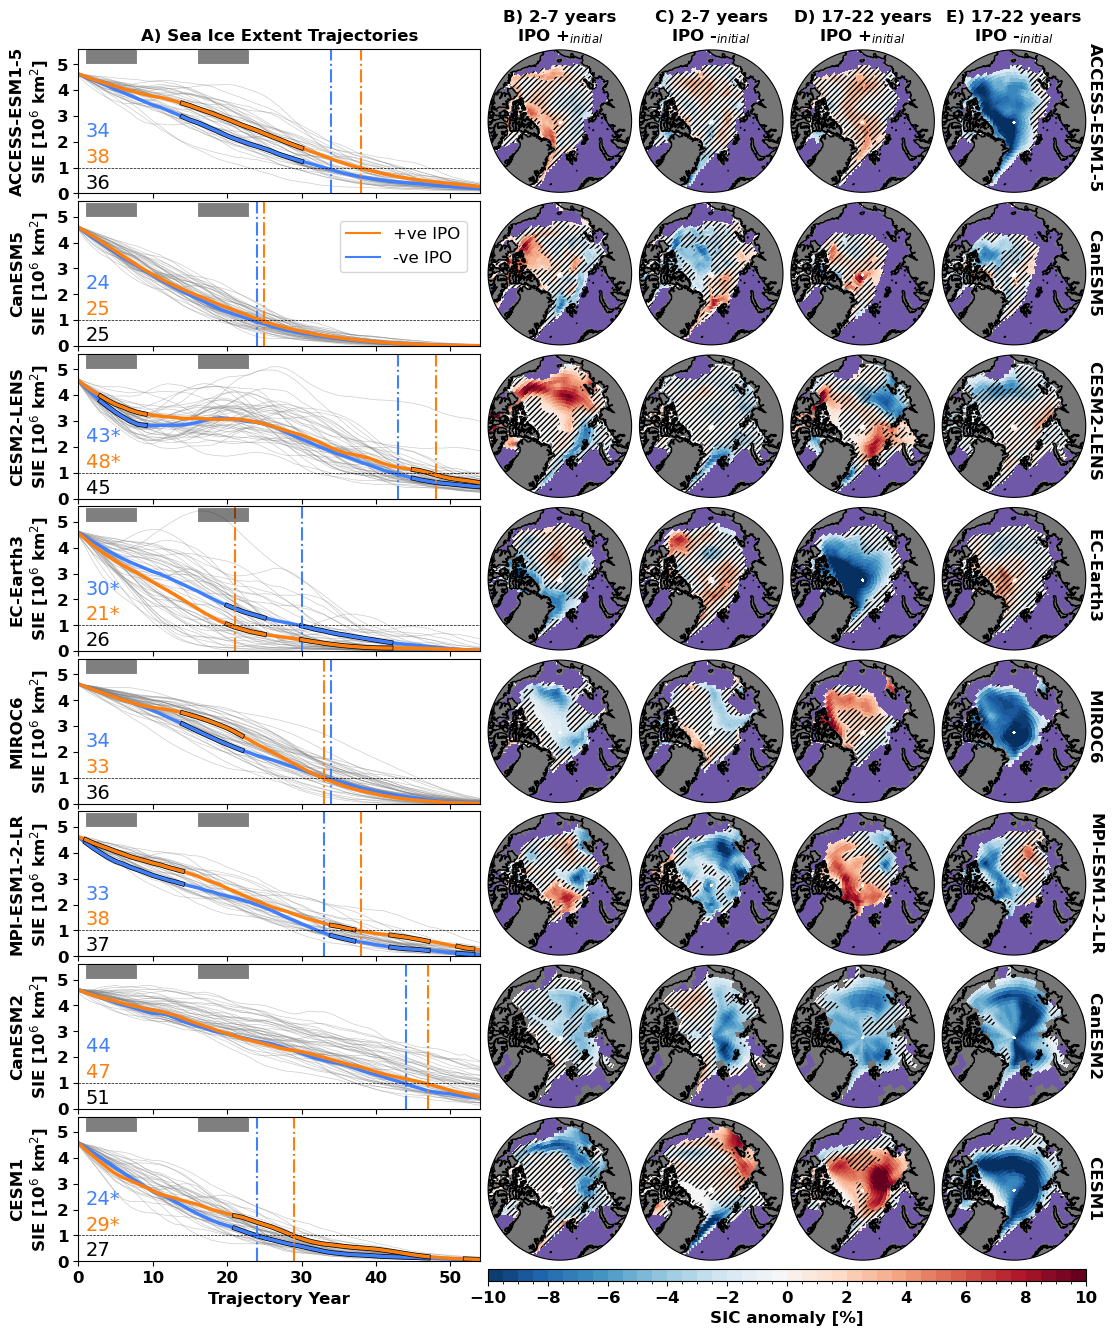

In [9]:
fig = plt.figure(figsize=(13,16))
gs = gridspec.GridSpec(
    9, 5,
    width_ratios=[2.8, 1, 1, 1, 1],
    height_ratios=[1,1,1,1,1,1,1,1,0.08], # last row = colorbar
    wspace=0.04,
    hspace=0.06
)

#Figure 2a
for model_i, model_name in enumerate(
    ['ACCESS-ESM1-5','CanESM5','CESM2-LENS','EC-Earth3',
     'MIROC6','MPI-ESM1-2-LR','CanESM2','CESM1']):

    ax_ts = fig.add_subplot(gs[model_i, 0])

    #list the ensemble mean IF year
    IF_in_phase = int(SIE_all_mem[model_name]['time'].where(
        (SIE_all_mem[model_name].mean('member') - 1) < 0).min())
    ax_ts.text(1, 0.2, str(IF_in_phase), color='k', fontsize=14)
    
   ### COLUMN 1 - plot the general IPO phase 
    SIE_all_mem[model_name].plot.line(
        x='time', ax=ax_ts, add_legend=False, c='0.5', 
        linewidth=0.5, alpha=0.4)

    IPO_neg_dict[model_name].plot(ax=ax_ts,c=[0.25,0.5,1],linewidth=2.5)
        
    IPO_neg_dict[model_name].where(p_val_IPO_only[model_name]==1).plot(
        ax=ax_ts,c=[0.25,0.5,1],linewidth=2.5,
        path_effects=[pe.Stroke(linewidth=3.5, foreground='k'), pe.Normal()])

    #plot the -ve IPO phase trajectory year of ice-free year
    try:
        IF_in_phase = int(IPO_neg_dict[model_name]['time'].where(
            (IPO_neg_dict[model_name] - 1) < 0).min())
        
        if model_name in ('CESM1','CESM2-LENS','EC-Earth3'):
            ax_ts.text(1, 2.2 ,str(IF_in_phase)+'*', color=[0.25,0.5,1], fontsize=14)
            ax_ts.axvline(IF_in_phase, linestyle='-.', color=[0.25,0.5,1])   
        else:
            ax_ts.text(1, 2.2 ,str(IF_in_phase), color=[0.25,0.5,1], fontsize=14)
            ax_ts.axvline(IF_in_phase, linestyle='-.', color=[0.25,0.5,1])   
    except ValueError:
        print(model_name, 'does not go ice-free')
    
    IPO_pos_dict[model_name].plot(ax=ax_ts,c='tab:orange',linewidth=2.5)

    IPO_pos_dict[model_name].where(p_val_IPO_only[model_name]==1).plot(
        ax=ax_ts,c='tab:orange',linewidth=2.5,
        path_effects=[pe.Stroke(linewidth=3.5, foreground='k'), pe.Normal()])

    #plot the +ve IPO phase trajectory year of ice-free year
    try:
        IF_in_phase = int(IPO_pos_dict[model_name]['time'].where(
            (IPO_pos_dict[model_name] - 1) < 0).min())
        
        if model_name in ('CESM1','CESM2-LENS','EC-Earth3'):
            ax_ts.text(1, 1.2, str(IF_in_phase)+"*", color='tab:orange', fontsize=14)
            ax_ts.axvline(IF_in_phase, linestyle='-.', color='tab:orange')   
        else:
            ax_ts.text(1, 1.2, str(IF_in_phase), color='tab:orange', fontsize=14)
            ax_ts.axvline(IF_in_phase, linestyle='-.', color='tab:orange')   
            
    except ValueError:
        print(model_name, 'does not go ice-free')
    
    ax_ts.axhline(1, c='k', linewidth=0.5, linestyle='--')
    ax_ts.set_ylim(0, 5.6)
    ax_ts.set_xlim(0, 54)            
    ax_ts.set_title('')  
    #plot grey box for time periods of spatial plots
    ax_ts.plot([2,7],[5.28,5.28], linewidth=10, c='k', alpha=0.5)
    ax_ts.plot([17,22],[5.28,5.28], linewidth=10, c='k', alpha=0.5)

    #set axes parameters
    if model_i == 1:
        ax_ts.plot([], [], c='tab:orange', label='+ve IPO')
        ax_ts.plot([], [], c=[0.25,0.5,1], label='-ve IPO')
        ax_ts.legend(fontsize=12, loc=[0.65, 0.51])

            
    ax_ts.set_yticks([0, 1, 2, 3, 4, 5])
    ax_ts.set_yticklabels([0, 1, 2, 3, 4, 5], fontsize=12, fontweight='bold')
    ax_ts.set_ylabel(model_name+'\n'+'SIE [10$^6$ km$^2$]', 
                          fontsize=12, fontweight='bold')
    
    if model_i < 7:
        ax_ts.set_xticklabels([])
        ax_ts.set_xlabel('')
    else:
        ax_ts.set_xticks([0, 10, 20, 30, 40, 50])
        ax_ts.set_xticklabels([0, 10, 20, 30, 40, 50],
                              fontsize=12, fontweight='bold')
        ax_ts.set_xlabel('Trajectory Year', fontsize=12, fontweight='bold')

    if model_i == 0:
        ax_ts.set_title('A) Sea Ice Extent Trajectories', fontsize=12, fontweight='bold')


#Figure 2b-e
lat_min = 68
levels_ = np.arange(-10,10.1,0.5)
title_list = ['B) 2-7 years'+'\n'+r'IPO +$_{initial}$', 
              'C) 2-7 years'+'\n'+'IPO -$_{initial}$',
              'D) 17-22 years'+'\n'+'IPO +$_{initial}$', 
              'E) 17-22 years'+'\n'+'IPO -$_{initial}$']

#this is the IF year
traj_start = [2,2,17,17]
traj_end = [7,7,22,22]


for model_i, model_name in enumerate(
    ['ACCESS-ESM1-5', 'CanESM5', 'CESM2-LENS', 'EC-Earth3',
     'MIROC6', 'MPI-ESM1-2-LR', 'CanESM2', 'CESM1']):  

    data_use = [IPO_pos[model_name].copy(), IPO_neg[model_name].copy(),
                IPO_pos[model_name].copy(), IPO_neg[model_name].copy(),]

    for phase_i in range(4):

        ens_mean = all_mem[model_name].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')
    
        ens_sd = all_mem_SD[model_name].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')

        ens_max_model = ens_max[model_name].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')

        if model_name == 'CanESM2': #need to mask out the land
            ens_mean = ens_mean.where(CanESM2_sftlf['sftlf']==0)

        #calculate t-test  95% confidence interval
        n = mem_n[model_name] #the number of ensemble members
        se = ens_sd/(n**0.5) #the standard error    
        ens_95_CI = se * stats.t.ppf((1 + 0.95) / 2, n-1)
    
        ax = fig.add_subplot(
            gs[model_i, phase_i+1],
            projection=ccrs.NorthPolarStereo(central_longitude=0)
        )
        ax.set_extent((-180,180,lat_min,90), ccrs.PlateCarree())

        #set boundary of subplots
        theta = np.linspace(0, 2*np.pi, 100) #make the plot circular
        center, radius = [0.5, 0.5], 0.5
        verts = np.vstack([np.sin(theta), np.cos(theta)]).T
        circle = mpath.Path(verts * radius + center)
        ax.set_boundary(circle, transform=ax.transAxes)
        ax.set_facecolor('1')

        data_plot = (data_use[phase_i].sel(trajectory_year=slice(
            traj_start[phase_i],traj_end[phase_i])).mean('trajectory_year')-ens_mean)
        
        plotting = data_plot.plot(transform=ccrs.PlateCarree(), levels=levels_, 
                       add_colorbar=False)

        #plot stipiling where difference exceeds the 95% confidence interval
        sig_data = ((data_plot*0)+1).where(np.absolute(data_plot)<ens_95_CI)
            
        ax.contourf(sig_data['lon'], sig_data['lat'], sig_data,
            transform=ccrs.PlateCarree(), colors='none', levels=[.5, 1.5], 
            hatches=['//////'], alpha=0)

        #color where no sea ice in purple?
        no_sea_ice = (ens_max_model.where(ens_max_model<15))*0 + 1
        no_sea_ice.plot(cmap='Purples_r', levels=np.arange(0.7,2,0.1), add_labels=False, 
                add_colorbar=False, transform=ccrs.PlateCarree(), 
                extend='neither', linewidths=0.0000000001, edgecolors='face')

        #shade land in gray
        land = (ens_mean>-999).where((ens_mean>-999)==0)
        land.plot(cmap='Greys_r', levels=np.arange(-0.5,1,0.1), add_labels=False, 
                add_colorbar=False, transform=ccrs.PlateCarree(), 
                extend='neither', linewidths=0.0000000001, edgecolors='face')
        
        if model_name == 'ACCESS-ESM1-5':
            ax.set_title(title_list[phase_i], fontweight='bold', fontsize=12)

        if phase_i == 3:
            ax.text(1.01, 0, model_names_title[model_i], fontsize=12,
                    fontweight='bold', transform=ax.transAxes, va='bottom', 
                    ha='left', rotation=270);

        ax.coastlines()        

cbar_ax = fig.add_subplot(gs[8, 1:5])  # only under maps
cb = fig.colorbar(plotting, cax=cbar_ax, extend='neither',
                  ticks=np.arange(-10,10.1,2), orientation='horizontal')
cb.ax.set_xlabel('SIC anomaly [%]', fontsize=12, fontweight='bold', color='0') 
cbtick_obj = plt.getp(cb.ax.axes, 'xticklabels')   
plt.setp(cbtick_obj, color='0', fontsize=12, fontweight='bold');

# fig.savefig('/glade/work/cwpowell/ice-free/figures/Figure_2.pdf',bbox_inches='tight')